Experiment No. 3
Experiment Name
Implementation and Analysis of Spatial Filtering Techniques using Low-Pass and High-Pass
Filters

Aim
To implement and analyze spatial domain filtering techniques using low-pass and high-pass
filters for image smoothing, noise reduction, edge enhancement, and feature preservation using
Python and OpenCV.

Purpose
Spatial filtering is one of the fundamental operations in digital image processing, used to
enhance image quality by modifying pixel values based on their neighboring pixels. Low-pass
filters are primarily used to reduce noise and smooth images, whereas high-pass filters
emphasize edges, fine details, and abrupt intensity changes, which are essential for feature
extraction and object recognition.
In this experiment, students will implement various spatial filtering techniques on real-world
images and evaluate their impact on image quality, edge preservation, and noise removal. The
experiment demonstrates the significance of filtering as a preprocessing step in computer vision
applications such as medical imaging, surveillance, remote sensing, and autonomous systems.

Prerequisites
• Basic knowledge of digital image processing
• Familiarity with Python programming
• Python libraries: OpenCV (cv2), NumPy, and Matplotlib
• Understanding of image kernels and convolution operations
• Jupyter Notebook, Google Colab, or Visual Studio Code


Steps

1. Import the required libraries and load a grayscale or color image for processing.
2. Display the original image and analyze its visual characteristics.
3. Apply Gaussian Blur to reduce image noise while preserving important structures.
4. Apply Median Filtering to remove impulse (salt-and-pepper) noise from the image.
5. Apply Average (Mean) Filtering and compare its smoothing performance with Gaussian
   filtering.
6. Implement Laplacian Filtering to enhance image edges and fine details.
7. Apply Sobel Edge Detection in both horizontal and vertical directions to detect image
   gradients.
8. Compare the outputs of different low-pass and high-pass filters in terms of noise
   reduction, edge preservation, and computational performance.
9. Display the original and filtered images along with suitable observations highlighting
   the strengths and limitations of each filtering technique.
10. Interpret the results and discuss the applications of spatial filtering in real-world
    computer vision systems.


Image shape: (477, 500)

Filtering execution time:
Gaussian filter : 0.466 ms
Median filter   : 2.644 ms
Average filter  : 1.201 ms
Laplacian filter: 4.314 ms
Sobel X filter  : 4.220 ms
Sobel Y filter  : 3.606 ms

PSNR with respect to the original image:
Gaussian filter : 28.03 dB
Median filter   : 34.21 dB
Average filter  : 27.51 dB


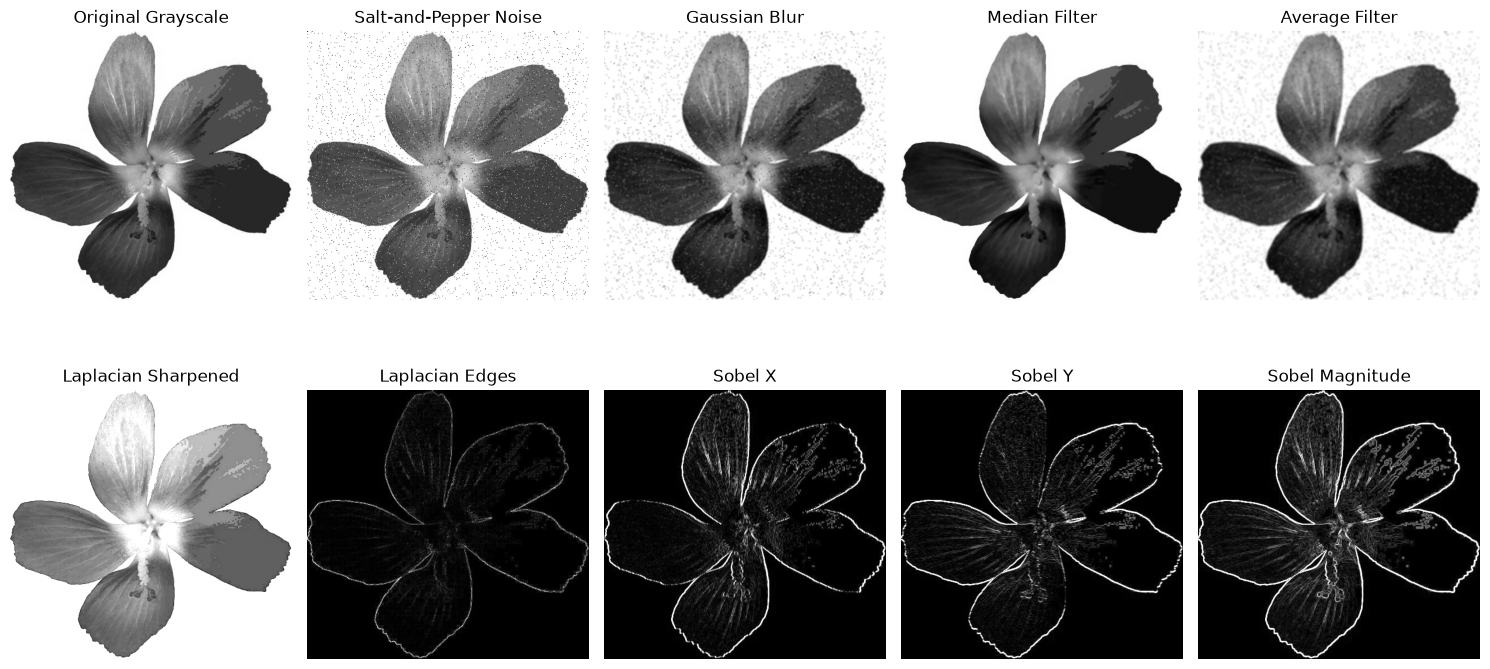

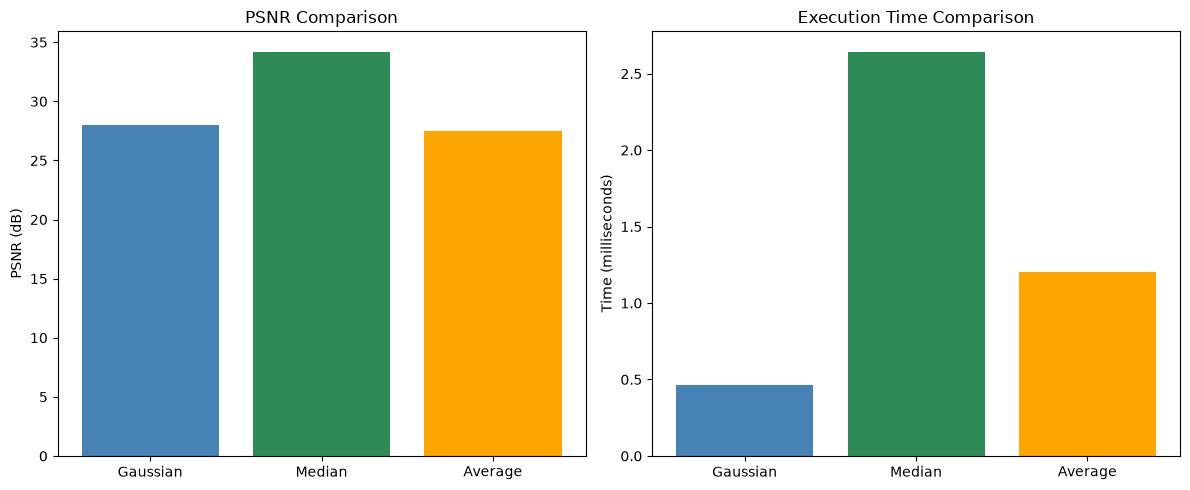

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# Load image
image_path = "sample.jpg"  # Change this to your image path
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Add salt-and-pepper noise for evaluating median filtering
noisy = gray.copy()
noise_probability = 0.03

random_values = np.random.random(gray.shape)
noisy[random_values < noise_probability / 2] = 0
noisy[random_values > 1 - noise_probability / 2] = 255

# Filtering function with execution time
def apply_filter(filter_function, input_image):
    start_time = time.perf_counter()
    output = filter_function(input_image)
    elapsed_time = (time.perf_counter() - start_time) * 1000
    return output, elapsed_time

# Low-pass filters
gaussian, gaussian_time = apply_filter(
    lambda img: cv2.GaussianBlur(img, (5, 5), 0), noisy
)

median, median_time = apply_filter(
    lambda img: cv2.medianBlur(img, 5), noisy
)

average, average_time = apply_filter(
    lambda img: cv2.blur(img, (5, 5)), noisy
)

# High-pass filters
laplacian, laplacian_time = apply_filter(
    lambda img: cv2.Laplacian(img, cv2.CV_64F), gray
)

laplacian_display = cv2.convertScaleAbs(laplacian)

sobel_x, sobel_x_time = apply_filter(
    lambda img: cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3), gray
)

sobel_y, sobel_y_time = apply_filter(
    lambda img: cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3), gray
)

sobel_x_display = cv2.convertScaleAbs(sobel_x)
sobel_y_display = cv2.convertScaleAbs(sobel_y)

sobel_magnitude = cv2.magnitude(
    sobel_x.astype(np.float32),
    sobel_y.astype(np.float32)
)
sobel_magnitude = cv2.convertScaleAbs(sobel_magnitude)

# High-pass sharpening using Laplacian
sharpened = cv2.addWeighted(
    gray, 1.5, laplacian_display, -0.5, 0
)

# Quality measurements
def mse(original, filtered):
    return np.mean((original.astype(np.float32) - filtered.astype(np.float32)) ** 2)

def psnr(original, filtered):
    error = mse(original, filtered)
    if error == 0:
        return float("inf")
    return 10 * np.log10((255 ** 2) / error)

print("Image shape:", gray.shape)
print("\nFiltering execution time:")
print(f"Gaussian filter : {gaussian_time:.3f} ms")
print(f"Median filter   : {median_time:.3f} ms")
print(f"Average filter  : {average_time:.3f} ms")
print(f"Laplacian filter: {laplacian_time:.3f} ms")
print(f"Sobel X filter  : {sobel_x_time:.3f} ms")
print(f"Sobel Y filter  : {sobel_y_time:.3f} ms")

print("\nPSNR with respect to the original image:")
print(f"Gaussian filter : {psnr(gray, gaussian):.2f} dB")
print(f"Median filter   : {psnr(gray, median):.2f} dB")
print(f"Average filter  : {psnr(gray, average):.2f} dB")

# Display low-pass filter results
plt.figure(figsize=(15, 8))

images = [
    (gray, "Original Grayscale"),
    (noisy, "Salt-and-Pepper Noise"),
    (gaussian, "Gaussian Blur"),
    (median, "Median Filter"),
    (average, "Average Filter"),
    (sharpened, "Laplacian Sharpened"),
    (laplacian_display, "Laplacian Edges"),
    (sobel_x_display, "Sobel X"),
    (sobel_y_display, "Sobel Y"),
    (sobel_magnitude, "Sobel Magnitude"),
]

for index, (img, title) in enumerate(images, start=1):
    plt.subplot(2, 5, index)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Compare filtering techniques using bar charts
filter_names = ["Gaussian", "Median", "Average"]
psnr_values = [
    psnr(gray, gaussian),
    psnr(gray, median),
    psnr(gray, average),
]

time_values = [gaussian_time, median_time, average_time]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(filter_names, psnr_values, color=["steelblue", "seagreen", "orange"])
plt.title("PSNR Comparison")
plt.ylabel("PSNR (dB)")

plt.subplot(1, 2, 2)
plt.bar(filter_names, time_values, color=["steelblue", "seagreen", "orange"])
plt.title("Execution Time Comparison")
plt.ylabel("Time (milliseconds)")

plt.tight_layout()
plt.show()

Questions

1. What is spatial filtering? How is it used in digital image processing?
2. Differentiate between Low-Pass Filters and High-Pass Filters with suitable examples.
3. Compare Average Filter, Gaussian Filter, and Median Filter based on their working
   principles and applications.
4. Why is the Median Filter particularly effective for removing salt-and-pepper noise?
5. Explain the role of convolution kernels in spatial filtering.
6. What is the purpose of the Sobel and Laplacian operators in edge detection?
7. Why are filtering operations considered an essential preprocessing step in computer
   vision?
8. Discuss the trade-off between image smoothing and edge preservation during filtering.
9. Mention four real-world applications where spatial filtering techniques are widely used.
10. Compare spatial domain filtering with frequency domain filtering in terms of
    implementation and practical applications


## Answers: Spatial Filtering in Digital Image Processing

### 1. What is spatial filtering? How is it used in digital image processing?

**Spatial filtering** is a technique in which the value of a pixel is modified based on the values of its neighboring pixels. It is performed directly on the **spatial domain** of an image.

A small matrix called a **filter, mask, or kernel** is moved across the image. At each position, the kernel combines the neighboring pixel values to produce a new pixel value.

**Uses include:**

- Removing noise
- Smoothing or blurring images
- Sharpening images
- Detecting edges
- Enhancing image details
- Preparing images for further computer-vision tasks

---

### 2. Differentiate between Low-Pass Filters and High-Pass Filters with suitable examples.

| Feature              | Low-Pass Filter (LPF)           | High-Pass Filter (HPF)               |
| -------------------- | ------------------------------- | ------------------------------------ |
| Main purpose         | Smooths the image               | Sharpens/enhances details            |
| Frequencies retained | Low frequencies                 | High frequencies                     |
| Effect               | Reduces rapid intensity changes | Emphasizes rapid intensity changes   |
| Removes              | Noise and fine details          | Smooth/background components         |
| Appearance           | Blurred/smoother image          | Sharper image                        |
| Examples             | Average filter, Gaussian filter | Laplacian, Sobel, sharpening filters |
| Applications         | Noise reduction, preprocessing  | Edge detection, image sharpening     |

**Example:** A Gaussian filter can blur an image by suppressing high-frequency components, while a Laplacian filter emphasizes edges by responding strongly to rapid intensity changes.

---

### 3. Compare Average Filter, Gaussian Filter, and Median Filter based on their working principles and applications.

| Filter              | Working Principle                                                            | Main Applications                                                     |
| ------------------- | ---------------------------------------------------------------------------- | --------------------------------------------------------------------- |
| **Average Filter**  | Replaces each pixel with the average of pixels in its neighborhood           | General smoothing and noise reduction                                 |
| **Gaussian Filter** | Uses a weighted average, giving greater importance to pixels near the center | Noise reduction, image smoothing, preprocessing before edge detection |
| **Median Filter**   | Replaces each pixel with the median value of its neighborhood                | Removing salt-and-pepper noise while preserving edges                 |

**Average Filter:**
All pixels within the kernel have equal weight. It is simple but can blur edges significantly.

**Gaussian Filter:**
Pixels closer to the center receive higher weights. This generally produces smoother and more natural-looking results than a simple average filter.

**Median Filter:**
The neighboring pixel values are sorted, and the middle value is selected. It is especially useful when the image contains impulse noise.

---

### 4. Why is the Median Filter particularly effective for removing salt-and-pepper noise?

Salt-and-pepper noise appears as isolated **very bright (salt)** and **very dark (pepper)** pixels.

The median filter replaces a pixel with the **median of its neighboring values**. Extreme values caused by noise usually occur at the ends of the sorted list, so they have little influence on the median.

For example:

`10, 11, 12, 13, 255`

The average is strongly affected by `255`, but the median is **12**, which is much closer to the surrounding pixels.

Therefore, the median filter can remove isolated noisy pixels while **preserving edges better than an average filter**.

---

### 5. Explain the role of convolution kernels in spatial filtering.

A **convolution kernel** is a small matrix containing numerical coefficients that determines how neighboring pixels contribute to the output pixel.

For example, a simple averaging kernel is:

[
K=\frac{1}{9}
\begin{bmatrix}
1&1&1\
1&1&1\
1&1&1
\end{bmatrix}
]

The kernel is moved across the image. At each location, its values are multiplied by the corresponding image pixels, the results are added, and the sum becomes the new pixel value.

Different kernels produce different effects:

- **Smoothing kernels** → reduce noise
- **Sharpening kernels** → enhance details
- **Sobel kernels** → detect edges
- **Laplacian kernels** → emphasize rapid intensity changes

Thus, the convolution kernel is essentially the **mathematical mechanism that defines the filtering operation**.

---

### 6. What is the purpose of the Sobel and Laplacian operators in edge detection?

Both are used to identify **edges**, where there is a rapid change in image intensity.

**Sobel Operator:**

- Uses first-order derivatives.
- Usually uses separate horizontal and vertical kernels.
- Detects edges in the **horizontal and vertical directions**.
- Provides some smoothing because its kernels incorporate neighboring pixels.
- Commonly used for detecting object boundaries.

**Laplacian Operator:**

- Uses the second-order derivative.
- Detects rapid intensity changes in multiple directions.
- Is sensitive to noise because differentiation emphasizes high-frequency changes.
- Often used after smoothing, such as Gaussian smoothing.

In short, **Sobel is useful for directional edge detection**, while **Laplacian provides a more direction-independent edge response**.

---

### 7. Why are filtering operations considered an essential preprocessing step in computer vision?

Filtering improves the quality of an image before more complex computer-vision algorithms are applied.

It can:

1. **Reduce noise**, making important features easier to detect.
2. **Remove unwanted details** that could confuse algorithms.
3. **Smooth images** before segmentation or edge detection.
4. **Enhance edges and structures** needed for feature extraction.
5. **Improve the reliability** of object detection, recognition, and tracking.

For example, applying Gaussian smoothing before edge detection can reduce noise-related false edges.

---

### 8. Discuss the trade-off between image smoothing and edge preservation during filtering.

Smoothing reduces noise and unwanted variations, but excessive smoothing can also remove important edges and fine details.

- **Strong smoothing:** Better noise reduction but greater loss of edges and details.
- **Weak smoothing:** Better edge preservation but more noise remains.

For example, an average filter can reduce noise effectively but may blur object boundaries. A median filter often provides a better balance for impulse noise because it removes extreme noisy pixels while preserving many edges.

Therefore, the **choice of filter and kernel size** should depend on the application and the type and amount of noise present.

---

### 9. Mention four real-world applications where spatial filtering techniques are widely used.

Four important applications are:

1. **Medical imaging** – noise reduction and enhancement of X-ray, CT, and MRI images.
2. **Surveillance and security** – improving video quality and detecting object boundaries.
3. **Satellite and remote sensing** – enhancing geographical features and reducing image noise.
4. **Autonomous vehicles/robotics** – preprocessing camera images for lane, object, and obstacle detection.

Other applications include facial recognition, industrial inspection, photography, and document processing.

---

### 10. Compare spatial domain filtering with frequency domain filtering in terms of implementation and practical applications.

| Feature            | Spatial Domain Filtering                    | Frequency Domain Filtering                                                             |
| ------------------ | ------------------------------------------- | -------------------------------------------------------------------------------------- |
| Operating domain   | Directly on image pixels                    | On the image's frequency representation                                                |
| Basic operation    | Kernel/convolution                          | Fourier transform → frequency filtering → inverse transform                            |
| Implementation     | Generally simpler                           | More computationally involved                                                          |
| Filters            | Average, Gaussian, Median, Sobel, Laplacian | Low-pass, high-pass, band-pass, notch filters                                          |
| Local processing   | Very convenient                             | Usually considers the image globally                                                   |
| Applications       | Noise removal, edge detection, sharpening   | Periodic noise removal, frequency analysis, advanced image enhancement                 |
| Computational cost | Often efficient for small kernels           | Transform operations can be computationally expensive, though FFT makes them practical |

**Spatial filtering** works directly with neighboring pixels, making it intuitive and highly suitable for local operations such as edge detection and noise removal.

**Frequency-domain filtering** first transforms the image using a Fourier transform. The image is then manipulated according to its frequency components and transformed back. It is particularly useful for analyzing and removing **periodic noise** and for designing frequency-selective filters.

**In summary:** spatial filtering is usually simpler and more intuitive for local image operations, whereas frequency-domain filtering is powerful when the problem is naturally described in terms of image frequencies.
